# CycleNet: Residual Cycle Forecasting (RCF) for Long-term Time Series Forecasting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/cyclenet_residual_cycle.ipynb)

**Paper**: *CycleNet: Enhancing Time Series Forecasting through Modeling Periodic Patterns* — Shengsheng Lin, Weiwei Lin, Xinyi Hu, Wentai Wu, Ruichao Mo, Haocheng Zhong. **NeurIPS 2024 (Spotlight)**. [arXiv:2409.18479](https://arxiv.org/abs/2409.18479)

**Official code**: [github.com/ACAT-SCUT/CycleNet](https://github.com/ACAT-SCUT/CycleNet)

**Key ideas**:
- **Residual Cycle Forecasting (RCF)**: a *learnable* recurrent cycle $Q \in \mathbb{R}^{W \times D}$ (one period of length $W$ per channel, initialised to zero) captures the periodic pattern shared by the whole series.
- The cycle is **removed** from the input, a tiny backbone forecasts the **residual**, and the cycle is **added back** to the output.
- **Cycle-index alignment**: each window carries the phase $t \bmod W$ of where it sits in the series so the right slice of $Q$ is used (the dataset must return it).
- **Backbones**: a single `Linear(L, H)` or a 2-layer `MLP(L → 512 → H)`, shared across channels (channel independence), with RevIN instance normalisation.

This notebook re-implements CycleNet from scratch in PyTorch (faithful to the official code) and trains both **CycleNet/Linear** and **CycleNet/MLP** on **ETTh1, lookback 96 → horizon 96**, all 7 channels (features = M), with $W = 24$ (daily cycle of hourly data).

## Setup
No extra packages are needed on Colab (torch, numpy, pandas, matplotlib, sklearn are pre-installed).

In [1]:
import time, json, random, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


## Data: ETTh1 with standard splits

Standard Informer/Autoformer/TSLib borders (train 12 months, val 4 months, test 4 months), `StandardScaler` fitted on the training rows only; metrics are computed on the scaled data (as reported in papers).

**Cycle index.** CycleNet needs to know the *phase* of every window inside the cycle of length $W$. The official data loader computes `cycle_index = (np.arange(len(data)) % W)[border1:border2]` over the **whole** series and returns `cycle_index[s_end]` (the phase of the first forecast step, i.e. global position `border1 + i + L`). We do exactly the same with `CycleWindowDataset`, which wraps the shared `WindowDataset` and also returns that integer. (Using `s_end` rather than `s_begin` only shifts which row of $Q$ is called "phase 0" — it is a constant relabelling, consistent between train and test.)

In [2]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

In [3]:
L, H, W = 96, 96, 24          # lookback, horizon, cycle length (24 h for hourly ETTh1)
n_tr, n_va = 12*30*24, 4*30*24
OFFSETS = {'train': 0, 'val': n_tr - L, 'test': n_tr + n_va - L}   # global row index of each split's first row

class CycleWindowDataset(WindowDataset):
    """WindowDataset that additionally returns the cycle index (phase) of each window."""
    def __init__(self, arr, L, H, offset, cycle_len, stride=1):
        super().__init__(arr, L, H, stride)
        self.offset, self.cycle_len = offset, cycle_len
    def __getitem__(self, k):
        x, y = super().__getitem__(k)
        i = self.idx[k]
        cyc = (self.offset + i + self.L) % self.cycle_len     # == official cycle_index[s_end]
        return x, y, torch.tensor(cyc, dtype=torch.long)

train, val, test, cols = load_etth1(L)
print('channels:', cols)
ds = {k: CycleWindowDataset(a, L, H, OFFSETS[k], W) for k, a in [('train', train), ('val', val), ('test', test)]}
for k, d in ds.items(): print(f'{k:5s}: {len(d)} windows')
x, y, c = ds['test'][0]
print('sample shapes:', tuple(x.shape), tuple(y.shape), 'cycle index:', int(c))

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train: 8449 windows
val  : 2785 windows
test : 2785 windows
sample shapes: (96, 7) (96, 7) cycle index: 0


## Residual Cycle Forecasting (RCF): the learnable recurrent cycle

$Q \in \mathbb{R}^{W \times D}$ is a free parameter (zeros at init). For a window whose phase is $c$, the cycle component aligned with a segment of length $n$ is obtained by cyclic indexing:

$$C_{c:n}[t, d] = Q[(c + t) \bmod W,\ d], \quad t = 0..n-1$$

This is the official vectorised implementation (gather with modulo index arithmetic, from PR #4).

In [4]:
class RecurrentCycle(nn.Module):
    def __init__(self, cycle_len, channel_size):
        super().__init__()
        self.cycle_len = cycle_len
        self.data = nn.Parameter(torch.zeros(cycle_len, channel_size))   # Q, learned end-to-end

    def forward(self, index, length):
        # index: (B,) phase of each window; returns (B, length, D)
        gather_index = (index.view(-1, 1) + torch.arange(length, device=index.device).view(1, -1)) % self.cycle_len
        return self.data[gather_index]

## CycleNet model

With RevIN instance normalisation (`use_revin=1` in the official configs):

1. $x \leftarrow (x - \mu) / \sqrt{\sigma^2 + 10^{-5}}$ per window and channel
2. **remove cycle**: $x' = x - C_{c:L}$
3. **backbone** on the residual (channel-independent, weights shared across channels): $\hat y' = f(x')$, with $f$ = `Linear(L, H)` or `Linear(L, 512) → ReLU → Linear(512, H)`
4. **add cycle back**: $\hat y = \hat y' + C_{(c+L) \bmod W : H}$
5. de-normalise: $\hat y \leftarrow \hat y \cdot \sqrt{\sigma^2+10^{-5}} + \mu$

In [5]:
class CycleNet(nn.Module):
    def __init__(self, seq_len, pred_len, enc_in, cycle_len, model_type='mlp', d_model=512, use_revin=True):
        super().__init__()
        self.seq_len, self.pred_len, self.cycle_len, self.use_revin = seq_len, pred_len, cycle_len, use_revin
        self.cycleQueue = RecurrentCycle(cycle_len, enc_in)
        assert model_type in ['linear', 'mlp']
        if model_type == 'linear':
            self.model = nn.Linear(seq_len, pred_len)
        else:
            self.model = nn.Sequential(nn.Linear(seq_len, d_model), nn.ReLU(), nn.Linear(d_model, pred_len))

    def forward(self, x, cycle_index):
        # x: (B, L, D), cycle_index: (B,)
        if self.use_revin:
            seq_mean = torch.mean(x, dim=1, keepdim=True)
            seq_var = torch.var(x, dim=1, keepdim=True) + 1e-5
            x = (x - seq_mean) / torch.sqrt(seq_var)
        x = x - self.cycleQueue(cycle_index, self.seq_len)                       # remove cycle
        y = self.model(x.permute(0, 2, 1)).permute(0, 2, 1)                     # forecast residual
        y = y + self.cycleQueue((cycle_index + self.seq_len) % self.cycle_len, self.pred_len)  # add cycle back
        if self.use_revin:
            y = y * torch.sqrt(seq_var) + seq_mean
        return y

for mt in ['linear', 'mlp']:
    m = CycleNet(L, H, 7, W, mt)
    print(f'CycleNet/{mt}: {sum(p.numel() for p in m.parameters()):,} parameters')

CycleNet/linear: 9,480 parameters
CycleNet/mlp: 99,080 parameters


## Training (official hyper-parameters)

From `scripts/CycleNet/{Linear,MLP}-Input-96/etth1.sh` and `run.py` defaults:

| | CycleNet/Linear | CycleNet/MLP |
|---|---|---|
| optimizer | Adam, lr 0.01 | Adam, lr 0.005 |
| batch size | 256 | 256 |
| epochs / patience | 30 / 5 (early stopping on val MSE) | 30 / 5 |
| lr schedule | `type3`: constant for 2 epochs, then ×0.8 per epoch | same |
| loss | MSE | MSE |

Training is extremely cheap (a few seconds per epoch), so we keep the official 30 epochs / patience 5. The train loader drops the last incomplete batch (as in the official code); val/test loaders do not.

In [6]:
from torch.utils.data import DataLoader

def evaluate(model, loader):
    model.eval(); se = ae = n = 0.0
    with torch.no_grad():
        for x, y, c in loader:
            x, y, c = x.to(device), y.to(device), c.to(device)
            p = model(x, c)
            se += ((p - y) ** 2).sum().item(); ae += (p - y).abs().sum().item(); n += y.numel()
    return se / n, ae / n

def predict(model, loader):
    model.eval(); P, Y, X = [], [], []
    with torch.no_grad():
        for x, y, c in loader:
            P.append(model(x.to(device), c.to(device)).cpu().numpy()); Y.append(y.numpy()); X.append(x.numpy())
    return np.concatenate(X), np.concatenate(Y), np.concatenate(P)

def type3_lr(base_lr, epoch):   # official adjust_learning_rate, lradj='type3' (epoch is 1-based)
    return base_lr if epoch < 3 else base_lr * (0.8 ** (epoch - 3))

def train_cyclenet(model_type, lr, epochs=30, patience=5, batch_size=256):
    seed_everything()
    g = torch.Generator(); g.manual_seed(SEED)
    tr_loader = DataLoader(ds['train'], batch_size=batch_size, shuffle=True, drop_last=True, generator=g)
    va_loader = DataLoader(ds['val'], batch_size=batch_size, shuffle=False)
    model = CycleNet(L, H, 7, W, model_type).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    best, best_state, bad = float('inf'), None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); losses = []
        for x, y, c in tr_loader:
            x, y, c = x.to(device), y.to(device), c.to(device)
            opt.zero_grad(); loss = crit(model(x, c), y); loss.backward(); opt.step()
            losses.append(loss.item())
        vmse, _ = evaluate(model, va_loader)
        flag = ''
        if vmse < best:
            best, best_state, bad, flag = vmse, copy.deepcopy(model.state_dict()), 0, '*'
        else:
            bad += 1
        print(f'[{model_type}] epoch {ep:2d} | train {np.mean(losses):.4f} | val {vmse:.4f} {flag}')
        if bad >= patience:
            print('early stopping'); break
        for gp in opt.param_groups: gp['lr'] = type3_lr(lr, ep)   # adjust_learning_rate(optim, epoch+1) after each epoch
    model.load_state_dict(best_state)
    return model, time.time() - t0

In [7]:
te_loader = DataLoader(ds['test'], batch_size=256, shuffle=False)
results = {}
models = {}
for model_type, lr in [('linear', 0.01), ('mlp', 0.005)]:
    model, secs = train_cyclenet(model_type, lr)
    mse, mae = evaluate(model, te_loader)
    models[model_type] = model
    results[model_type] = dict(mse=mse, mae=mae, seconds=secs, params=sum(p.numel() for p in model.parameters()))
    print(f'==> CycleNet/{model_type}: test MSE {mse:.4f}  MAE {mae:.4f}  ({secs:.1f}s)\n')

[linear] epoch  1 | train 0.4086 | val 0.7151 *


[linear] epoch  2 | train 0.3587 | val 0.7099 *


[linear] epoch  3 | train 0.3554 | val 0.7067 *


[linear] epoch  4 | train 0.3552 | val 0.7251 


[linear] epoch  5 | train 0.3538 | val 0.7105 


...

[mlp] epoch  7 | train 0.3233 | val 0.6938 


[mlp] epoch  8 | train 0.3202 | val 0.6991 


[mlp] epoch  9 | train 0.3166 | val 0.6906 


[mlp] epoch 10 | train 0.3134 | val 0.6888 


[mlp] epoch 11 | train 0.3108 | val 0.6842 
early stopping
==> CycleNet/mlp: test MSE 0.3779  MAE 0.3994  (2.8s)



## What did the recurrent cycle learn?

$Q$ is a learned 24-hour profile per channel (in the RevIN-normalised space). Row 0 corresponds to the phase of `s_end` (see the data section).

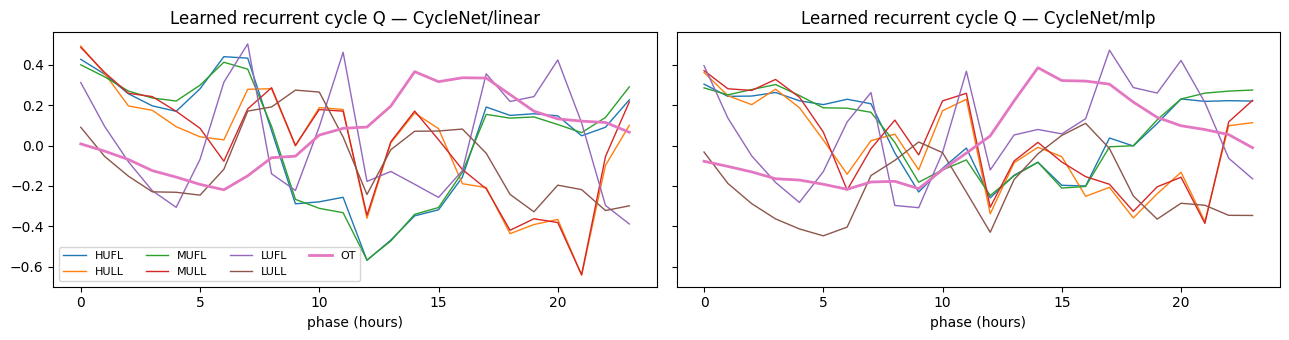

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for ax, mt in zip(axes, ['linear', 'mlp']):
    Q = models[mt].cycleQueue.data.detach().cpu().numpy()
    for d, name in enumerate(cols):
        ax.plot(Q[:, d], label=name, lw=2 if name == 'OT' else 1)
    ax.set_title(f'Learned recurrent cycle Q — CycleNet/{mt}'); ax.set_xlabel('phase (hours)')
axes[0].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## Forecast plot (OT channel)

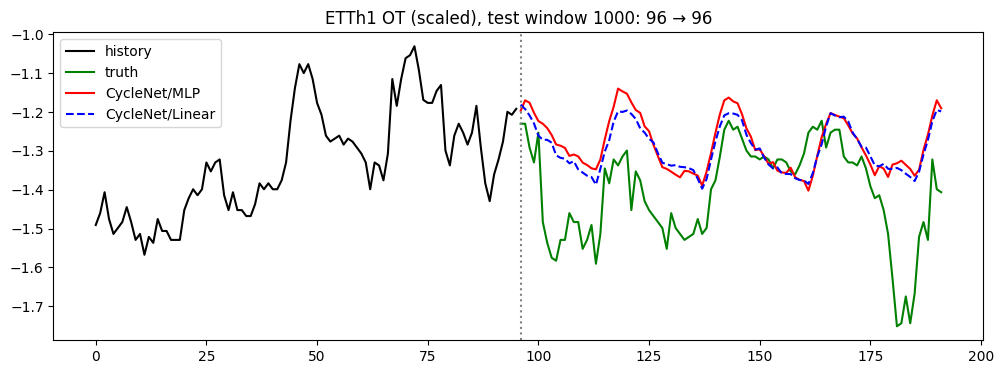

In [9]:
PRIMARY = 'mlp'   # the paper's best ETTh1 L=96, H=96 MSE is CycleNet/MLP (0.375); Linear has the better MAE (0.391)
X, Y, P = predict(models[PRIMARY], te_loader)
_, _, P_lin = predict(models['linear'], te_loader)
k, ot = 1000, cols.index('OT')
t_in, t_out = np.arange(L), np.arange(L, L + H)
plt.figure(figsize=(12, 4))
plt.plot(t_in, X[k, :, ot], 'k', label='history')
plt.plot(t_out, Y[k, :, ot], 'g', label='truth')
plt.plot(t_out, P[k, :, ot], 'r', label='CycleNet/MLP')
plt.plot(t_out, P_lin[k, :, ot], 'b--', label='CycleNet/Linear')
plt.axvline(L, color='gray', ls=':')
plt.title(f'ETTh1 OT (scaled), test window {k}: {L} → {H}'); plt.legend(); plt.show()

## Results

Test set: all 2785 stride-1 windows, MSE/MAE averaged over windows × horizon × 7 channels (scaled data). Paper numbers are from Table 7 of the paper (L = 96, mean of 5 seeds).

In [10]:
PAPER = {'linear': (0.378, 0.391), 'mlp': (0.375, 0.395)}
print(f"{'model':18s} {'MSE':>7s} {'MAE':>7s}   {'paper MSE':>9s} {'paper MAE':>9s}   params   train s")
for mt in ['linear', 'mlp']:
    r = results[mt]
    print(f"CycleNet/{mt:9s} {r['mse']:7.4f} {r['mae']:7.4f}   {PAPER[mt][0]:9.3f} {PAPER[mt][1]:9.3f}   {r['params']:6d}   {r['seconds']:.1f}")
print('\nReference (TSLib, ETTh1 96→96): DLinear 0.386/0.400, PatchTST 0.414/0.419, iTransformer 0.386/0.405, TimesNet 0.384/0.402')

out = {
    'model': 'CycleNet/MLP (primary); CycleNet/Linear also reported',
    'paper': 'CycleNet: Enhancing Time Series Forecasting through Modeling Periodic Patterns (arXiv 2409.18479)',
    'venue': 'NeurIPS 2024 (Spotlight)',
    'type': 'supervised',
    'lookback': L, 'horizon': H,
    'mse': results[PRIMARY]['mse'], 'mae': results[PRIMARY]['mae'],
    'paper_mse': PAPER[PRIMARY][0], 'paper_mae': PAPER[PRIMARY][1],
    'params': results[PRIMARY]['params'],
    'train_or_infer_seconds': results['linear']['seconds'] + results['mlp']['seconds'],
    'variants': {f'CycleNet/{mt}': dict(mse=results[mt]['mse'], mae=results[mt]['mae'], paper_mse=PAPER[mt][0],
                                        paper_mae=PAPER[mt][1], params=results[mt]['params'],
                                        train_seconds=results[mt]['seconds']) for mt in ['linear', 'mlp']},
    'notes': ('From-scratch re-implementation of the official CycleNet (RCF, W=24, RevIN, channel-independent backbone). '
              'Official ETTh1 hyper-params: Adam, batch 256, lr 0.01 (Linear) / 0.005 (MLP, d_model 512), 30 epochs, patience 5, '
              'lradj type3. Single seed 2024 (paper averages 5 seeds). features=M, all 7 channels, stride-1 test (2785 windows).'),
}
try:
    with open(f'results_{"cyclenet_residual_cycle"}.json', 'w') as f: json.dump(out, f, indent=2)
    print('saved results_cyclenet_residual_cycle.json')
except Exception as e:
    print('could not save results:', e)

model                  MSE     MAE   paper MSE paper MAE   params   train s
CycleNet/linear     0.3814  0.3923       0.378     0.391     9480   3.5
CycleNet/mlp        0.3779  0.3994       0.375     0.395    99080   2.8

Reference (TSLib, ETTh1 96→96): DLinear 0.386/0.400, PatchTST 0.414/0.419, iTransformer 0.386/0.405, TimesNet 0.384/0.402
saved results_cyclenet_residual_cycle.json


## Using your own data

1. Load your series as a `(T, D)` float array, split chronologically and scale with statistics from the training part (replace `load_etth1`).
2. **Pick the cycle length `W`**: the dominant period of your data in time steps — e.g. 24 for hourly data with a daily cycle, 96 for 15-min data, 168 for hourly data with a weekly cycle (Electricity/Traffic in the paper). The ACF peak is a good guide.
3. Give `CycleWindowDataset` the **global row offset** of each split (`OFFSETS`) so that the phase `(offset + i + L) % W` is consistent across train/val/test — this is what aligns the learned cycle with real time.
4. Choose a backbone: `model_type='linear'` (tiny, very strong on long horizons) or `'mlp'`. Set `enc_in = D`.
5. Train with `train_cyclenet(model_type, lr)` and evaluate with `evaluate`. For forecasting the future, the phase of a new window is simply `(global index of its first forecast step) % W`.